# Selection on structural variants — main figures

Condensed versions of the results in `sv_selection_key_results.ipynb` (full per-context panels, tables
and robustness there). Three figures, one per question:

1. **Figure 1** — in the 231 founders, SVs carry the signature of purifying selection, graded by function.
2. **Figure 2** — in GrENE-Net, the same class keeps losing ground; climate sorts lineages, not SVs.
3. **Figure 3** — the purified SVs are TE- and repeat-derived insertions into exons, in nature and in
   the experiment alike.

**Unit and filters** (as in the key-results notebook): the SV **event** (arch3 alleles of a pangenome
bubble merged with `truvari collapse` defaults); called in ≥ 90% of the 231 founders throughout;
≥ 2 carrier founders for the GrENE-Net analyses and the composition panels, singletons included in the
spectra (Figure 1a–b, 3a). Context, first match wins: CDS > UTR > intron > reference TE > promoter
(≤ 2 kb upstream) > intergenic. Colours: insertions orange, deletions green, SNPs black, short indels grey.

In [1]:

import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
plt.rcParams.update({'figure.dpi':120,'font.size':8,'axes.linewidth':0.6,'savefig.bbox':'tight'})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive"))
CTX=["CDS","UTR","intron","TE","promoter","intergenic"]
KC={"snp":"0.15","indel":"0.62","ins":"#D95F02","del":"#1B9E77"}; KL={"snp":"SNPs","indel":"short indels","ins":"insertions","del":"deletions"}
OC={"cold-specific":"#2166AC","shared":"0.45","warm-specific":"#B2182B"}
def style(ax,axis="both"):
    ax.set_axisbelow(True); ax.grid(color="0.9",lw=0.6,axis=axis)
    for sp in ax.spines.values(): sp.set_visible(False)
def panel(ax,letter): ax.annotate(letter,xy=(-0.12,1.04),xycoords="axes fraction",fontsize=11,fontweight="bold")
rng=np.random.default_rng(0)
D=pd.read_csv(f"{G}/sv_event_catalog.csv"); PALL=np.load(f"{G}/sv_event_catalog_p_poolaf.npy")   # kMate pool allele frequencies (seed mix + each garden)
ok=D.passes.to_numpy(); E=D[ok].reset_index(drop=True); PE=PALL[ok]
CS=np.load(f"{G}/classic_sfs.npz"); M=int(CS["M"])
def maf(name): c=CS[f"{name}_c"].astype(float); k=CS[f"{name}_k"].astype(float); f=c/k; return np.minimum(f,1-f)
def tajD(names):
    # Tajima's D of a class, directly from its variants (no projection): per variant, c carriers among k called founders
    names=[names] if isinstance(names,str) else names
    c=np.concatenate([CS[f"{n}_c"] for n in names]).astype(float); k=np.concatenate([CS[f"{n}_k"] for n in names]).astype(float)
    h=2*c*(k-c)/(k*(k-1)); n=int(np.median(k)); j=np.arange(1,n); a1=(1/j).sum(); a2=(1/j**2).sum()
    b1=(n+1)/(3*(n-1)); b2=2*(n*n+n+3)/(9*n*(n-1)); c1=b1-1/a1; c2=b2-(n+2)/(a1*n)+a2/a1**2; e1=c1/a1; e2=c2/(a1**2+a2)
    D=lambda hh:(hh.sum()-hh.size/a1)/np.sqrt(e1*hh.size+e2*hh.size*(hh.size-1))
    return D(h),h,D
def tajD_ci(names,B=300):
    d,h,D=tajD(names)
    if h.size>20000:                                  # large SNP classes: CI is negligible, fewer draws
        bs=[D(rng.choice(h,h.size)) for _ in range(40)]
    else: bs=[D(rng.choice(h,h.size)) for _ in range(B)]
    return d,np.percentile(bs,2.5),np.percentile(bs,97.5)
print(f"events passing: {len(E):,} ({(E.kind=='ins').sum():,} insertions, {(E.kind=='del').sum():,} deletions)")
# robustness checks (`_sv_main_figures_checks.py`): matched-SNP-set null for the load statistic, founder
# origin in the burden model, spectra without singletons
CKM=pd.read_csv(f"{G}/main_fig_checks_lmm.csv").set_index("check")
CKS=pd.read_csv(f"{G}/main_fig_checks_nosingleton.csv")
pfmt=lambda p: "p < 0.001" if p<=0.001 else f"p = {p:.2g}"


events passing: 18,418 (12,981 insertions, 5,437 deletions)


## Figure 1 — Purifying selection on SVs in the founders

Top row insertions (**a–c**), bottom row deletions (**d–f**); the same three views in each.

**(a, d)** Folded site-frequency spectra as cumulative distributions of minor-allele frequency (no
binning), in coding sequence (left) and in introns (right): the SV class against the neutral reference
(synonymous SNPs, dashed grey) and the known-selected comparator (nonsynonymous SNPs, black). A line above the neutral one = a class shifted towards rare variants,
the footprint of purifying selection. Two-sample Kolmogorov–Smirnov *D* against synonymous SNPs in each
panel — the largest vertical gap to the neutral line. **(b, e)** Tajima's *D* per genomic context,
the SV class against SNPs of the same context (dumbbells; 95% bootstrap CI; Δ = SV − SNP), with the
synonymous and nonsynonymous SNP references as vertical lines. Contexts in
the same order in both rows. **(c, f)** Where the class is found: share of the class in each context
divided by the context's share of genomic length (1 = uniform placement), against SNPs.

*Statistics.* Folded MAF per variant = min(c/k, 1 − c/k), c carriers among k called founders
(k ≥ 208 of 231, 1 ≤ c ≤ k − 1; singletons included). Tajima's *D* (Tajima 1989) computed directly from
the variants of a class — π = Σ 2c(k − c)/(k(k − 1)), S = number of variants, sample size = median *k* —
with a 95% CI from bootstrap resampling of variants. **Synonymous SNPs** (the alternate base leaves the amino acid unchanged) are the
putatively neutral reference; **nonsynonymous SNPs** (the amino acid changes, or a stop is gained or
lost) are the class known to be under purifying selection. Each coding SNP is called from the
reference codon and the codon carrying the alternate base (standard code, TAIR10 sequence,
representative `.1` gene models). The stricter 4-fold / 0-fold degenerate-site version gives the same
picture (values printed below).
*Reading frame (not drawn; numbers printed below):* 44% of CDS insertions and 44% of CDS deletions have
a length that is a multiple of 3, against 33% of insertions elsewhere; among CDS insertions the
enrichment is carried by duplicated gene sequence (59%), TE-derived insertions are at 33%.

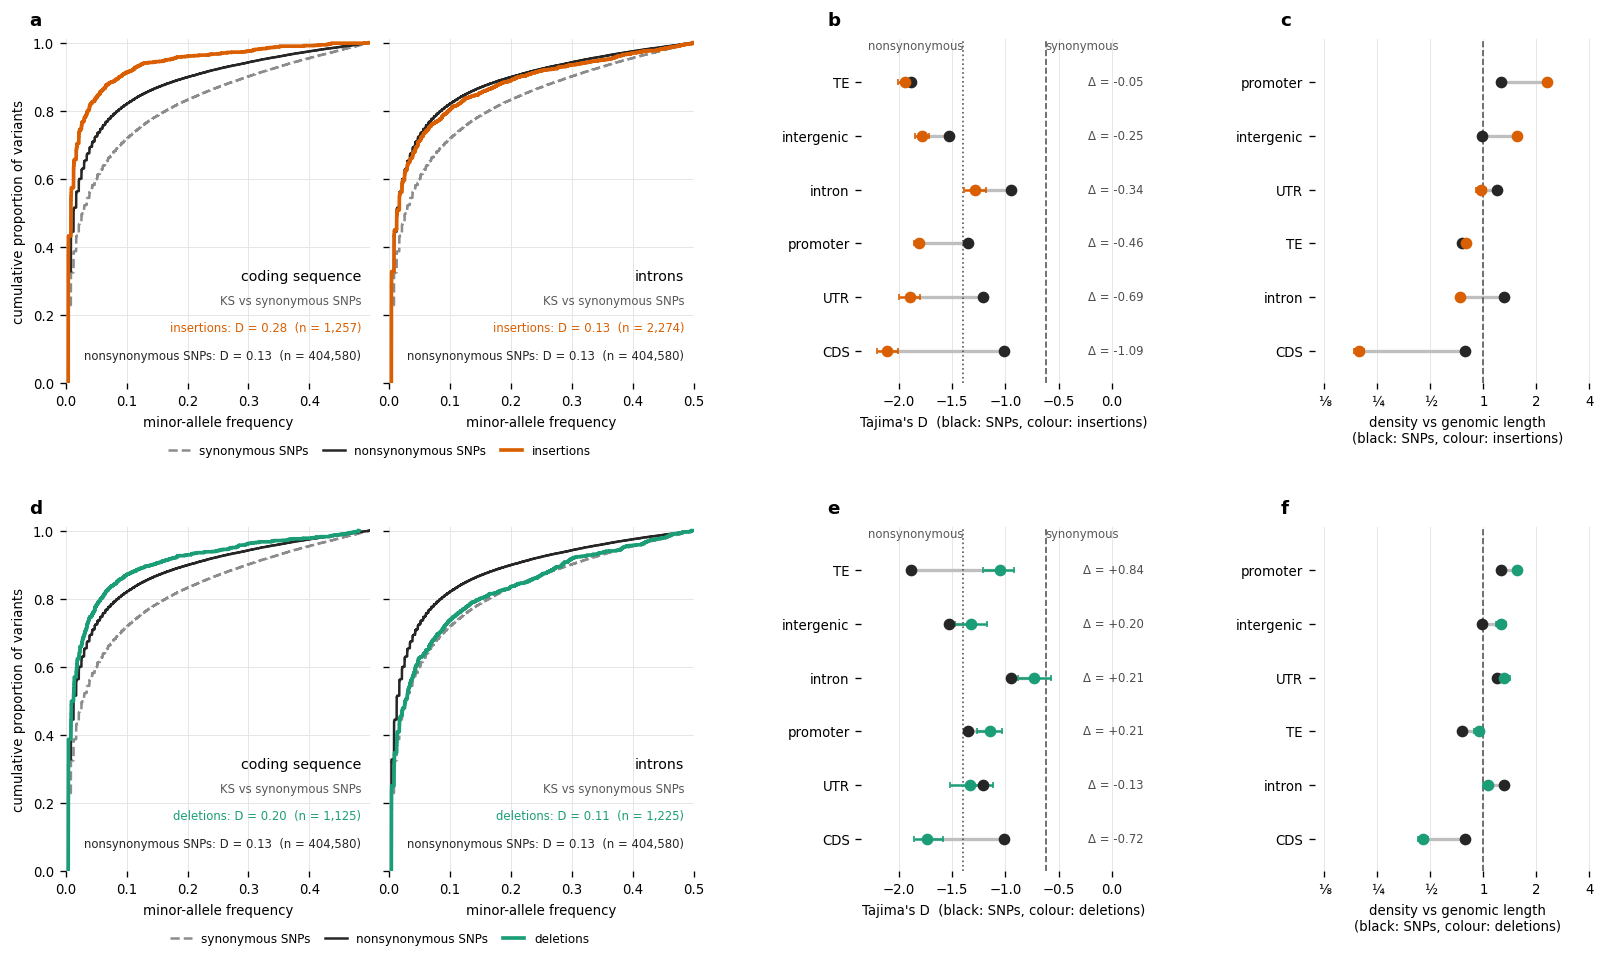

Figure 1a,d  cumulative spectra; KS vs synonymous SNPs:
      kind context                cls      n  maf_lt1  maf_lt5  maf_lt10  KS_D  KS_p
insertions     CDS    synonymous SNPs 394676    0.325    0.599     0.716 0.000   1.0
insertions     CDS nonsynonymous SNPs 404580    0.445    0.724     0.819 0.132   0.0
insertions     CDS         insertions   1257    0.574    0.837     0.912 0.277   0.0
insertions  intron    synonymous SNPs 394676    0.325    0.599     0.716 0.000   1.0
insertions  intron nonsynonymous SNPs 404580    0.445    0.724     0.819 0.132   0.0
insertions  intron         insertions   2274    0.450    0.709     0.802 0.128   0.0
 deletions     CDS    synonymous SNPs 394676    0.325    0.599     0.716 0.000   1.0
 deletions     CDS nonsynonymous SNPs 404580    0.445    0.724     0.819 0.132   0.0
 deletions     CDS          deletions   1125    0.499    0.778     0.870 0.197   0.0
 deletions  intron    synonymous SNPs 394676    0.325    0.599     0.716 0.000   1.0
 deletion

In [2]:

REF=maf("snp_syn")
def ecdf(a,v,**k):
    v=np.sort(v); a.step(np.r_[v[0],v],np.r_[0,np.arange(1,v.size+1)/v.size],where="post",**k)
fig=plt.figure(figsize=(16.5,9)); gs_=fig.add_gridspec(2,3,width_ratios=[2.2,1,1],wspace=0.42,hspace=0.42)
GSH=pd.read_csv(f"{G}/context_genome_share.csv").set_index("context").share.reindex(CTX).to_numpy()
S=np.load(f"{G}/sv_sfs_context_origin_event.npz"); m=S["snp_n"]>=2; ns=np.bincount(S["snp_ctx"][m],minlength=6); snp_sh=ns/ns.sum(); rs=snp_sh/GSH
TD={name:tajD_ci(name) for name in ["snp_syn","snp_nonsyn","snp_4fold","snp_0fold"]+[f"{k}_{x}" for k in ("snp","ins","del") for x in CTX]}
# context order fixed across rows (by the insertion result), so the two rows read against each other
order=sorted(CTX,key=lambda x: TD[f"ins_{x}"][0]-TD[f"snp_{x}"][0])
ni_=E[E.kind=="ins"].context.value_counts().reindex(CTX).to_numpy(); order_c=[CTX[i] for i in np.argsort((ni_/ni_.sum())/GSH)]
SF=[]; DENS={}
for r,(k,let) in enumerate((("ins","abc"),("del","def"))):
    KN=KL[k]
    # (a/d) folded SFS as cumulative distributions of minor-allele frequency; 4-fold SNPs = neutral reference, 0-fold = known-selected
    gsa=gs_[r,0].subgridspec(1,2,wspace=0.06); a1=fig.add_subplot(gsa[0,0]); a2=fig.add_subplot(gsa[0,1],sharey=a1)
    for a,x,ttl in ((a1,"CDS","coding sequence"),(a2,"intron","introns")):
        style(a); txt=[]
        for name,lab,col,ls,lw in (("snp_syn","synonymous SNPs","0.55","--",1.5),("snp_nonsyn","nonsynonymous SNPs","0.15","-",1.5),(f"{k}_{x}",KN,KC[k],"-",2.2)):
            v=maf(name); ks=stats.ks_2samp(v,REF); ecdf(a,v,color=col,ls=ls,lw=lw,label=lab)
            if name!="snp_syn": txt.append((f"{lab}: D = {ks.statistic:.2f}  (n = {v.size:,})",col))
            SF.append(dict(kind=KN,context=x,cls=lab,n=v.size,maf_lt1=(v<0.01).mean(),maf_lt5=(v<0.05).mean(),maf_lt10=(v<0.10).mean(),KS_D=ks.statistic,KS_p=ks.pvalue))
        a.set_xlim(0,0.5); a.set_ylim(0,1.01); a.set_xlabel("minor-allele frequency"); a.set_xticks([0,0.1,0.2,0.3,0.4]+([0.5] if x=="intron" else []))
        a.annotate(ttl,xy=(0.97,0.29),xycoords="axes fraction",ha="right",va="bottom",fontsize=8.5)
        a.annotate("KS vs synonymous SNPs",xy=(0.97,0.22),xycoords="axes fraction",ha="right",va="bottom",fontsize=7,color="0.35")
        for q,(s_,col) in enumerate(txt[::-1]): a.annotate(s_,xy=(0.97,0.14-0.08*q),xycoords="axes fraction",ha="right",va="bottom",fontsize=7,color=col)
    a1.set_ylabel("cumulative proportion of variants"); a2.tick_params(labelleft=False); panel(a1,let[0])
    h_,l_=a1.get_legend_handles_labels(); a1.legend(h_,l_,frameon=False,fontsize=7.2,loc="upper center",bbox_to_anchor=(1.03,-0.15),ncol=3,columnspacing=1.2,handlelength=1.8)
    # (b/e) Tajima's D, the class against SNPs of the same context
    a=fig.add_subplot(gs_[r,1]); style(a,axis="x"); panel(a,let[1])
    for i,x in enumerate(order):
        s,v_=TD[f"snp_{x}"],TD[f"{k}_{x}"]; a.plot([s[0],v_[0]],[i,i],color="0.75",lw=2,zorder=1)
        a.errorbar(s[0],i,xerr=[[s[0]-s[1]],[s[2]-s[0]]],fmt="o",color=KC["snp"],ms=6,capsize=2,zorder=3)
        a.errorbar(v_[0],i,xerr=[[v_[0]-v_[1]],[v_[2]-v_[0]]],fmt="o",color=KC[k],ms=6,capsize=2,zorder=3)
        a.annotate(f"Δ = {v_[0]-s[0]:+.2f}",xy=(0.99,i),xycoords=("axes fraction","data"),ha="right",va="center",fontsize=7,color="0.3")
    for name,lab,ls in (("snp_syn","synonymous","--"),("snp_nonsyn","nonsynonymous",":")):
        a.axvline(TD[name][0],color="0.35",lw=1,ls=ls); a.annotate(lab,xy=(TD[name][0],len(order)-0.45),fontsize=7,ha="right" if name=="snp_nonsyn" else "left",va="bottom",color="0.35")
    a.set_yticks(range(len(order))); a.set_yticklabels(order); a.set_ylim(-0.6,len(order)-0.2); a.set_xlim(TD["ins_CDS"][1]-0.15,TD["snp_syn"][0]+0.95)
    a.set_xlabel(f"Tajima's D  (black: SNPs, colour: {KN})")
    # (c/f) where the class is found: share in context / share of genomic length
    a=fig.add_subplot(gs_[r,2]); style(a,axis="x"); panel(a,let[2]); a.axvline(1,color="0.35",lw=1,ls="--")
    nk=E[E.kind==k].context.value_counts().reindex(CTX).to_numpy(); sh=nk/nk.sum(); rk=sh/GSH; DENS[KN]=rk
    for j,x in enumerate(order_c):
        i=CTX.index(x); a.plot([rs[i],rk[i]],[j,j],color="0.75",lw=2,zorder=1)
        a.errorbar(rs[i],j,xerr=1.96*np.sqrt(snp_sh[i]*(1-snp_sh[i])/ns.sum())/GSH[i],fmt="o",color=KC["snp"],ms=6,capsize=2,zorder=3)
        a.errorbar(rk[i],j,xerr=1.96*np.sqrt(sh[i]*(1-sh[i])/nk.sum())/GSH[i],fmt="o",color=KC[k],ms=6,capsize=2,zorder=3)
    a.set_xscale("log",base=2); a.set_xticks([0.125,0.25,0.5,1,2,4]); a.set_xticklabels(["⅛","¼","½","1","2","4"]); a.set_xlim(0.11,4.6)
    a.set_yticks(range(6)); a.set_yticklabels(order_c); a.set_ylim(-0.6,5.8); a.set_xlabel(f"density vs genomic length\n(black: SNPs, colour: {KN})")
fig.savefig(f"{G}/plots/main_fig1.png",dpi=200); fig.savefig(f"{G}/plots/main_fig1.pdf"); plt.show()
print("Figure 1a,d  cumulative spectra; KS vs synonymous SNPs:"); print(pd.DataFrame(SF).drop_duplicates(["kind","context","cls"]).round(3).to_string(index=False))
print("\nneutral reference check — synonymous / nonsynonymous vs the stricter 4-fold / 0-fold sites:")
print(pd.DataFrame([dict(cls=n_,n=maf(n_).size,maf_lt5=(maf(n_)<0.05).mean(),TajD=TD[n_][0]) for n_ in ("snp_syn","snp_4fold","snp_nonsyn","snp_0fold")]).round(3).to_string(index=False))
print("\nFigure 1b,e  Tajima's D [95% CI]:"); print(pd.DataFrame({k_:dict(D=v[0],lo=v[1],hi=v[2]) for k_,v in TD.items()}).T.round(2).to_string())
print("\nFigure 1c,f  share / genomic share:"); print(pd.DataFrame(dict(genome=GSH,SNPs=rs,**DENS),index=CTX).round(2).to_string())
# reading frame (not drawn): share of events whose length is a multiple of 3 (1/3 expected outside coding sequence)
I=E[E.kind=="ins"]; C=I[I.context=="CDS"]; rows=[]
for lab,d in (("CDS insertions, gene duplicate",C[C.seq_class=="gene_dup"]),("CDS insertions, TE-derived",C[C.seq_class=="te_derived"]),("all CDS insertions",C),
              ("CDS deletions",E[(E.kind=="del")&(E.context=="CDS")]),("insertions, other contexts",I[I.context!="CDS"])):
    x_=int((d.size_bp%3==0).sum()); n=len(d); ci=stats.binomtest(x_,n,1/3).proportion_ci(); rows.append(dict(group=lab,n=n,in_frame=x_/n,lo=ci.low,hi=ci.high))
print("\nreading frame (not drawn):"); print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nrobustness — with singletons (1) and without (minor-allele count >= 2): share MAF < 5%, KS D vs synonymous SNPs")
print(CKS.pivot(index="cls",columns="min_minor_count",values=["maf_lt5","KS_D"]).reindex(["snp_syn","snp_nonsyn","ins_CDS","ins_UTR","ins_intron","ins_TE","ins_promoter","ins_intergenic","del_CDS"]).round(3).to_string())


## Figure 2 — GrENE-Net: is the selection still acting?

kMate estimates, for every pooled sample, the founder (ecotype) composition *h* from the k-mers and
derives each variant's allele frequency from it; within GrENE-Net a variant therefore moves with the
founders that carry it. The test of selection on SVs is at the founder level (a–b); (c–d) show the
same experiment at the level of the variants themselves, using kMate's stored per-pool allele
frequencies (`_sv_garden_af.py`): the founding frequency is the mean of the 8 seed-mix runs, and a
garden's frequency is the mean over its plots of each plot's frequency at its last sampled generation
(352 pools, 31 gardens). An SV event's frequency is the sum of its alleles' frequencies (capped at 1).

**(a)** Founder burden. For each founder *f*, mean log-fitness over the 31 gardens,
*y*<sub>*f*</sub> = mean<sub>*s*</sub> log[(*H*<sub>0,*f*</sub> + Δ*H*<sub>*s*,*f*</sub> + 10⁻⁵) /
(*H*<sub>0,*f*</sub> + 10⁻⁵)], with *H*<sub>0</sub> the founding ecotype frequency (mean of 8 seed-mix
estimates) and *H*<sub>0</sub> + Δ*H*<sub>*s*</sub> the last-generation ecotype frequency in garden *s*
(plots equally weighted). The mixed model, fit by REML, is

> *y* = β₀ + β₁·z(*r*<sub>context</sub>) + β₂·z(*r*<sub>intergenic</sub>) + β₃·z(call rate, SVs) +
> β₄·z(call rate, SNPs) + β₅·[sequencing route] + *u* + ε,  *u* ~ N(0, σ²<sub>g</sub>**K**),
> ε ~ N(0, σ²<sub>e</sub>**I**)

where *r*<sub>context</sub> = (variants of the class carried) / (variants of the class called) for
the founder, *r*<sub>intergenic</sub> the same for intergenic variants of the same kind and origin
(the within-class baseline), z(·) standardises to unit SD, and **K** is the SNP kinship matrix
(standardised GRM from a 2% SNP draw). Shown: β₁ ± 1.96 SE (Wald), shared variants (carried by both
cold- and warm-origin founders), per context and variant kind. **(b)** The same relation in the raw
data: founder mean log-fitness against the standardised shared-CDS-insertion burden, one point per
founder coloured by origin temperature, with the OLS line and 95% band (the mixed model in (a) adds
the covariates and the kinship term). **(c)** Population load. Expected number of a class's variants
per genome, *L* = Σ<sub>*v*</sub> *p*<sub>*v*</sub>, at the start (seed mix) and in each garden. Per
garden: log[*L*<sub>garden</sub>/*L*<sub>0</sub>] for **all CDS insertions** minus the same for CDS SNPs
re-weighted to the insertions' joint distribution of carrier count (10 bins) and mean carrier-origin
temperature (quintiles), so the comparison SNPs started at the same frequencies on the same kind of
founders. One dot per garden against the garden's temperature: purifying selection shows as an offset
below zero across the whole range, lineage sorting would show as a slope. Solid line and band = mean
± 95% CI over gardens; dotted = OLS on temperature; deletions alongside. The p-value is **empirical**:
gardens share one founder pool and are not independent, so the observed mean is compared with 1,000
random sets of CDS SNPs drawn with the same carrier-count × carrier-climate composition as the class
(one-sided for insertions, two-sided for deletions). **(d)** Climate of origin × garden climate. For variants private
to cold-origin or to warm-origin founders, the log load change per garden, log[*L*<sub>garden</sub>/*L*<sub>0</sub>],
regressed on garden temperature (OLS over 31 gardens; slope ± 1.96 SE), for insertions, deletions,
short indels and SNPs alike. A negative slope = the class loses more in warmer gardens.

/tmp/ipykernel_1006401/1831202582.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); fig.savefig(f"{G}/plots/main_fig2.png",dpi=200); fig.savefig(f"{G}/plots/main_fig2.pdf"); plt.show()


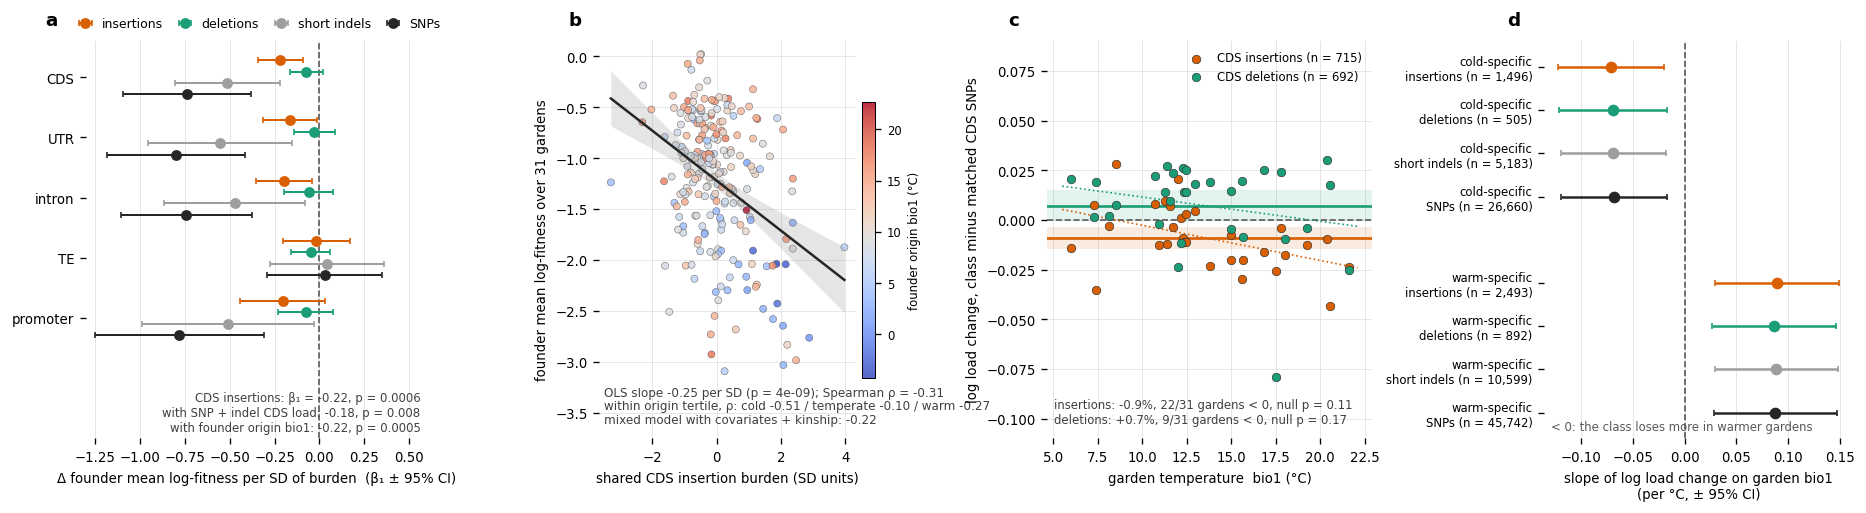

Figure 2a  β₁ per SD, shared variants (p):
context                   CDS              UTR           intron            TE        promoter
kind                                                                                         
deletions        -0.07 (0.12)     -0.03 (0.61)      -0.06 (0.4)  -0.05 (0.37)    -0.08 (0.33)
short indels  -0.51 (0.00059)   -0.55 (0.0069)    -0.47 (0.018)   +0.04 (0.8)   -0.51 (0.038)
insertions    -0.22 (0.00059)    -0.16 (0.033)    -0.20 (0.013)  -0.02 (0.86)   -0.21 (0.087)
SNPs          -0.74 (4.7e-05)  -0.80 (4.3e-05)  -0.74 (7.2e-05)  +0.03 (0.86)  -0.78 (0.0011)

Figure 2c  all CDS insertions: mean -0.0089, 22/31 below 0; slope on garden bio1 -0.0018/°C (p = 0.009)

Figure 2c  all CDS deletions: mean +0.0073, 9/31 below 0; slope on garden bio1 -0.0012/°C (p = 0.22)

Figure 2d  log load change vs garden bio1, OLS over 31 gardens:
       origin          cls     n  slope_per_C      se       p  mean_log_change
cold-specific   insertions  1496     -0.07

In [3]:

R=pd.read_csv(f"{G}/sv_burden_lmm_event.csv"); J=pd.read_csv(f"{G}/sv_burden_lmm_joint_event.csv")
GS=np.load(f"{G}/garden_af_event.npz"); PV=GS["p"].astype(np.float64); KD=GS["kind"].astype(str); CX=GS["ctx"]; ZN=GS["zone"].astype(str); ORG=GS["origin"].astype(str); BIO=GS["bio1"]
CB=np.array([2,3,4,5,6,8,11,16,26,51,1000]); BQ=np.quantile(GS["b1"][KD=="snp"],[0.2,0.4,0.6,0.8])
CELL=np.digitize(GS["n"],CB)*10+np.digitize(GS["b1"],BQ); SH=(GS["nc"]>0)&(GS["nw"]>0); zc=np.where(ZN=="cold","#2166AC",np.where(ZN=="hot","#B2182B","0.6"))
def snp_baseline(cell_sv,m_snp):
    cs=pd.Series(cell_sv).value_counts(); cn=pd.Series(CELL[m_snp]).value_counts(); w=(cs/cn).reindex(CELL[m_snp]).fillna(0).to_numpy()
    Ln=np.nansum(PV[m_snp]*w[:,None],0); return np.log(Ln[1:]/Ln[0]), np.isin(cell_sv,cn.index)
def load_diff(p_sv,cell_sv,m_snp):
    base,kp=snp_baseline(cell_sv,m_snp); Ls=np.nansum(p_sv[kp],0); return np.log(Ls[1:]/Ls[0])-base
def matched_null(cell_sv,m_snp,ndraw=1000,seed=1):
    # random sets of SNPs with the class's carrier-count x carrier-climate composition (one SNP per event, drawn within its cell), same statistic
    r=np.random.default_rng(seed); base,_=snp_baseline(cell_sv,m_snp); si=np.where(m_snp)[0]; sc_=CELL[si]
    pools={c:si[sc_==c] for c in np.unique(cell_sv)}; sizes={c:int((cell_sv==c).sum()) for c in pools}; out=np.empty(ndraw)
    for t in range(ndraw):
        pick=np.concatenate([r.choice(pools[c],sizes[c]) for c in pools if pools[c].size]); Ls=np.nansum(PV[pick],0); out[t]=(np.log(Ls[1:]/Ls[0])-base).mean()
    return out
def null_p(obs,null,two_sided=False):
    return (np.abs(null-null.mean())>=abs(obs-null.mean())).mean() if two_sided else (null<=obs).mean()
fig,ax=plt.subplots(1,4,figsize=(19,4.3),gridspec_kw=dict(width_ratios=[1.05,0.85,1.0,0.95],wspace=0.55))
# (a) forest
a=ax[0]; style(a,axis="x"); panel(a,"a"); a.axvline(0,color="0.35",lw=1,ls="--"); C5=["CDS","UTR","intron","TE","promoter"]
for j,k in enumerate(("ins","del","indel","snp")):
    d=R[(R.freq=="all")&(R.kind==k)&(R.origin=="shared")].set_index("context").reindex(C5); y=np.arange(5)+(j-1.5)*0.19
    a.errorbar(d.beta,y,xerr=1.96*d.se,fmt="o",ms=5.5,color=KC[k],ecolor=KC[k],elinewidth=1.2,capsize=2,label=KL[k])
a.set_yticks(range(5)); a.set_yticklabels(C5); a.set_ylim(6.0,-0.6); a.set_xlim(-1.3,0.6)
a.legend(frameon=False,fontsize=7.5,loc="lower center",bbox_to_anchor=(0.5,1.0),ncol=4,handletextpad=0.3,columnspacing=0.8)
a.set_xlabel("Δ founder mean log-fitness per SD of burden  (β₁ ± 95% CI)")
h=R[(R.kind=="ins")&(R.origin=="shared")&(R.context=="CDS")&(R.freq=="all")].iloc[0]; j2=J[J.term=="ins_shared_CDS_all"].set_index("model")
b1_=CKM.loc["+ founder origin bio1"]
a.annotate(f"CDS insertions: β₁ = {h.beta:+.2f}, p = {h.p:.1g}\nwith SNP + indel CDS load: {j2.loc['ins + SNP + indel','beta']:+.2f}, p = {j2.loc['ins + SNP + indel','p']:.1g}\nwith founder origin bio1: {b1_.beta:+.2f}, p = {b1_.p:.1g}",
           xy=(0.98,0.01),xycoords="axes fraction",ha="right",va="bottom",fontsize=7,color="0.25")
# (b) raw data: founder fitness vs burden
a=ax[1]; style(a); panel(a,"b")
FB=pd.read_csv(f"{G}/founder_burden_event.csv",dtype={"founder":str}); Zf=np.load(os.path.join(G,"..","..","..","r3_persite_gwas","results","ecotype_fitness","founder_site_dh.npz"),allow_pickle=True)
assert np.array_equal(Zf["founders"].astype(str),FB.founder.to_numpy())
Y=np.log((Zf["H0"][None,:]+Zf["DH_rel"]+1e-5)/(Zf["H0"][None,:]+1e-5)); ymean=Y.mean(0)
FO=pd.read_csv(f"{G}/sv_origin_partition_founders.csv",dtype={"founder":str}).set_index("founder").reindex(FB.founder)
rate=(FB.ins_shared_CDS_all/FB.called_ins_shared_CDS_all).to_numpy(); zb=(rate-rate.mean())/rate.std()
sc_=a.scatter(zb,ymean,c=FO.bio1.to_numpy(),cmap="coolwarm",s=18,alpha=0.85,linewidth=0.3,edgecolor="0.3")
m=sm.OLS(ymean,sm.add_constant(zb)).fit(); xx=np.linspace(zb.min(),zb.max(),50); pr=m.get_prediction(sm.add_constant(xx)); ci=pr.conf_int()
a.plot(xx,pr.predicted_mean,color="0.15",lw=1.5); a.fill_between(xx,ci[:,0],ci[:,1],color="0.5",alpha=0.2,lw=0)
cb=plt.colorbar(sc_,ax=a,pad=0.02,fraction=0.05); cb.set_label("founder origin bio1 (°C)",fontsize=7); cb.ax.tick_params(labelsize=7)
a.set_xlabel("shared CDS insertion burden (SD units)"); a.set_ylabel("founder mean log-fitness over 31 gardens"); a.set_ylim(-3.75,0.15)
wg=" / ".join(f"{g} {CKM.loc[f'Spearman within {g}-origin founders','beta']:+.2f}" for g in ("cold","temperate","warm"))
a.annotate(f"OLS slope {m.params[1]:+.2f} per SD (p = {m.pvalues[1]:.1g}); Spearman ρ = {stats.spearmanr(zb,ymean).statistic:+.2f}\nwithin origin tertile, ρ: {wg}\nmixed model with covariates + kinship: {h.beta:+.2f}",
           xy=(0.02,0.03),xycoords="axes fraction",fontsize=7.2,color="0.25",va="bottom")
# (c) load per garden: ALL CDS insertions / deletions vs CDS SNPs matched on carrier count x carrier climate, against garden temperature
a=ax[2]; style(a); panel(a,"c"); a.axhline(0,color="0.35",lw=1,ls="--"); LD={}; snpC=(KD=="snp")&(CX==0); xx=np.linspace(BIO.min()-0.5,BIO.max()+0.5,50); NOTE=[]
for j,k in enumerate(("ins","del")):
    ms=(KD==k)&(CX==0); d=load_diff(PV[ms],CELL[ms],snpC); LD[k]=d
    pe=null_p(d.mean(),matched_null(CELL[ms],snpC),two_sided=(k=="del")); lr=stats.linregress(BIO,d)
    m_,se_=d.mean(),d.std(ddof=1)/np.sqrt(d.size)
    a.axhspan(m_-1.96*se_,m_+1.96*se_,color=KC[k],alpha=0.12,lw=0); a.axhline(m_,color=KC[k],lw=1.6)
    a.plot(xx,lr.intercept+lr.slope*xx,color=KC[k],lw=1,ls=":")
    a.scatter(BIO,d,s=26,color=KC[k],edgecolor="0.2",linewidth=0.4,zorder=3,label=f"CDS {KL[k]} (n = {int(ms.sum()):,})")
    NOTE.append(f"{KL[k]}: {100*m_:+.1f}%, {(d<0).sum()}/31 gardens < 0, null {pfmt(pe)}")
a.set_xlabel("garden temperature  bio1 (°C)"); a.set_ylabel("log load change, class minus matched CDS SNPs"); a.set_ylim(-0.11,0.09)
a.legend(frameon=False,fontsize=7,loc="upper right"); a.annotate("\n".join(NOTE),xy=(0.02,0.03),xycoords="axes fraction",va="bottom",fontsize=7,color="0.25")
# (d) origin x garden: log load change per garden, slope on garden temperature, by origin class and variant kind
a=ax[3]; style(a,axis="x"); panel(a,"d"); a.axvline(0,color="0.35",lw=1,ls="--"); rows=[]; yl=[]
for i,o in enumerate(("cold-specific","warm-specific")):
    for j,k in enumerate(("ins","del","indel","snp")):
        m=(ORG==o)&(KD==k); L=np.nansum(PV[m],0); dl=np.log(L[1:]/L[0]); lr=stats.linregress(BIO,dl); y=i*5+j
        a.errorbar(lr.slope,y,xerr=1.96*lr.stderr,fmt="o",ms=6,color=KC[k],capsize=2); yl.append((y,f"{o}\n{KL[k]} (n = {int(m.sum()):,})"))
        rows.append(dict(origin=o,cls=KL[k],n=int(m.sum()),slope_per_C=lr.slope,se=lr.stderr,p=lr.pvalue,mean_log_change=dl.mean()))
a.set_yticks([y for y,_ in yl]); a.set_yticklabels([l for _,l in yl],fontsize=7); a.set_ylim(8.6,-0.6)
a.set_xlabel("slope of log load change on garden bio1\n(per °C, ± 95% CI)")
a.annotate("< 0: the class loses more in warmer gardens",xy=(0.02,0.02),xycoords="axes fraction",fontsize=7,color="0.35")
fig.tight_layout(); fig.savefig(f"{G}/plots/main_fig2.png",dpi=200); fig.savefig(f"{G}/plots/main_fig2.pdf"); plt.show()
print("Figure 2a  β₁ per SD, shared variants (p):")
t=R[(R.freq=="all")&(R.origin=="shared")].copy(); t["c"]=t.beta.map("{:+.2f}".format)+" ("+t.p.map("{:.2g}".format)+")"
print(t.pivot(index="kind",columns="context",values="c")[C5].rename(index=KL).to_string())
for k in ("ins","del"):
    lr=stats.linregress(BIO,LD[k]); print(f"\nFigure 2c  all CDS {KL[k]}: mean {LD[k].mean():+.4f}, {(LD[k]<0).sum()}/31 below 0; slope on garden bio1 {lr.slope:+.4f}/°C (p = {lr.pvalue:.2g})")
print("\nFigure 2d  log load change vs garden bio1, OLS over 31 gardens:"); print(pd.DataFrame(rows).round(5).to_string(index=False))


### Supplementary to Figure 2c — CDS insertions and deletions by climate of origin

The same statistic as panel c, for every origin class of CDS event: **all** events, then **shared**
(carried by cold- and warm-origin founders), **cold-specific** (≥ 2 cold-origin carriers, no
warm-origin) and **warm-specific** (the mirror). Each class is compared with CDS SNPs of the **same
origin class**, re-weighted to the class's carrier-count × carrier-temperature composition, so a
cold-specific insertion is judged against cold-specific SNPs that sit on the same kind of founder
background. One dot per garden, bars = mean ± 95% CI, empirical p from 1,000 matched SNP sets
(two-sided).

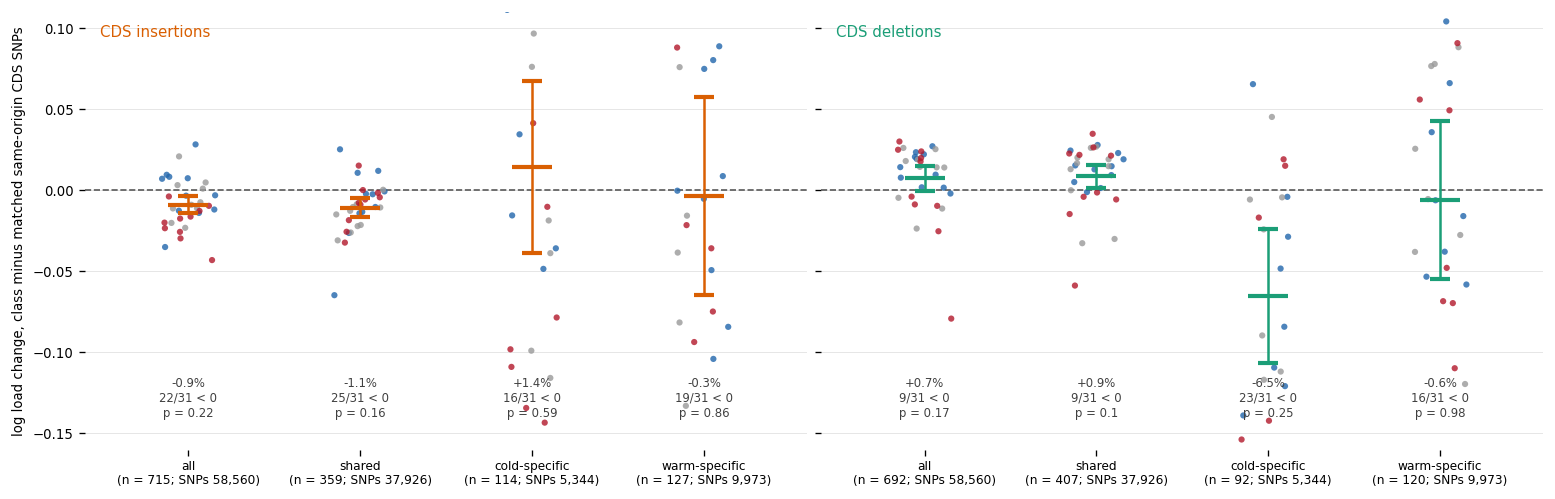

Supplement to 2c  CDS events by origin class vs same-origin matched CDS SNPs:
      kind        origin  n_events  n_snps    mean  gardens_below  null_p_two_sided
insertions           all       715   58560 -0.0089             22             0.216
insertions        shared       359   37926 -0.0108             25             0.161
insertions cold-specific       114    5344  0.0143             16             0.594
insertions warm-specific       127    9973 -0.0033             19             0.858
 deletions           all       692   58560  0.0073              9             0.170
 deletions        shared       407   37926  0.0086              9             0.103
 deletions cold-specific        92    5344 -0.0653             23             0.249
 deletions warm-specific       120    9973 -0.0061             16             0.979


In [4]:

fig,ax=plt.subplots(1,2,figsize=(13,4.2),sharey=True); rows=[]
for a,k in zip(ax,("ins","del")):
    style(a,axis="y"); a.axhline(0,color="0.35",lw=1,ls="--"); TL=[]
    for j,(lab,o) in enumerate((("all",None),("shared","shared"),("cold-specific","cold-specific"),("warm-specific","warm-specific"))):
        mo=np.ones(KD.size,bool) if o is None else (ORG==o); ms=mo&(KD==k)&(CX==0); mn=mo&(KD=="snp")&(CX==0)
        d=load_diff(PV[ms],CELL[ms],mn); pe=null_p(d.mean(),matched_null(CELL[ms],mn),two_sided=True)
        a.scatter(j+rng.uniform(-0.16,0.16,d.size),d,c=zc,s=14,alpha=0.8,linewidth=0,zorder=2)
        m_,se_=d.mean(),d.std(ddof=1)/np.sqrt(d.size); a.errorbar(j,m_,yerr=1.96*se_,fmt="_",ms=24,mew=2.5,color=KC[k],capsize=6,zorder=3)
        a.annotate(f"{100*m_:+.1f}%\n{(d<0).sum()}/31 < 0\n{pfmt(pe)}",xy=(j,-0.115),ha="center",va="top",fontsize=7,color="0.25")
        TL.append(f"{lab}\n(n = {int(ms.sum()):,}; SNPs {int(mn.sum()):,})")
        rows.append(dict(kind=KL[k],origin=lab,n_events=int(ms.sum()),n_snps=int(mn.sum()),mean=m_,gardens_below=int((d<0).sum()),null_p_two_sided=pe))
    a.set_xticks(range(4)); a.set_xticklabels(TL,fontsize=7.3); a.set_xlim(-0.6,3.6); a.set_ylim(-0.16,0.11)
    a.annotate(f"CDS {KL[k]}",xy=(0.02,0.97),xycoords="axes fraction",va="top",fontsize=9,color=KC[k])
ax[0].set_ylabel("log load change, class minus matched same-origin CDS SNPs")
fig.tight_layout(); fig.savefig(f"{G}/plots/supp_fig2c_by_origin.png",dpi=200); plt.show()
print("Supplement to 2c  CDS events by origin class vs same-origin matched CDS SNPs:"); print(pd.DataFrame(rows).round(4).to_string(index=False))


## Figure 3 — Which SVs are purified?

**(a)** Nature against experiment, one point per class of CDS insertion. *x*: Tajima's *D* in the
founders (95% bootstrap CI; vertical lines = synonymous and nonsynonymous SNP references). *y*: GrENE-Net load
change of the class's events relative to matched CDS SNPs (Figure 2c statistic), mean ±
95% CI over the 31 gardens. Inserted-sequence classes from BLAST of the inserted sequence against
TAIR10 (`insertion_tair10_class.csv`): TE-derived, duplicated gene sequence, other (dispersed / local)
duplication, novel (< 50% of the sequence aligns). **(b)** The experimental side of (a) garden by
garden: load change of each class relative to matched CDS SNPs, one small dot per garden, large marker
= mean ± 95% CI. **(c)** What insertions are made of, by context: composition of insertion events by
inserted-sequence class.

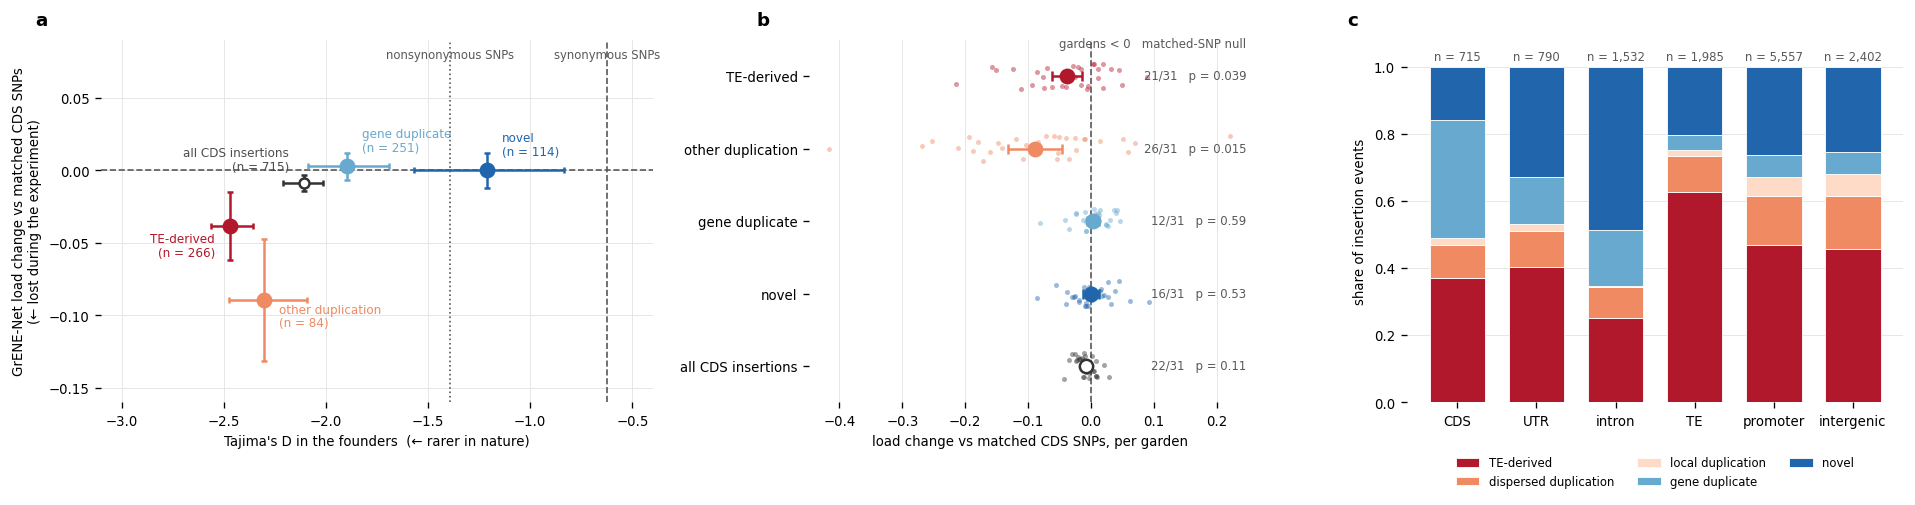

Figure 3a:
               cls   n   TajD     lo     hi   load  load_se  gardens_below  p_matched_null  null_sd
        TE-derived 266 -2.471 -2.564 -2.357 -0.038    0.012             21           0.039    0.020
 other duplication  84 -2.304 -2.474 -2.095 -0.089    0.022             26           0.015    0.033
    gene duplicate 251 -1.899 -2.086 -1.691  0.003    0.005             12           0.588    0.011
             novel 114 -1.214 -1.572 -0.836  0.000    0.006             16           0.532    0.012
all CDS insertions 715 -2.108 -2.211 -2.015 -0.009    0.003             22           0.110    0.007

Figure 3c  composition by context:
seq_class   dispersed duplication  gene duplicate  local duplication  novel  TE-derived
context                                                                                
CDS                         0.097           0.351              0.021  0.159       0.372
UTR                         0.109           0.139              0.022  0.328       0.403
i

In [5]:

I=E[E.kind=="ins"].copy(); C=I[I.context=="CDS"].copy(); iC=np.where((E.kind=="ins")&(E.context=="CDS"))[0]
snpCDS=(KD=="snp")&(CX==0); cellE=np.digitize(E.n_carriers,CB)*10+np.digitize(E.carrier_bio1,BQ)
SUB=[("TE-derived",["insCDS_te_derived"],(C.seq_class=="te_derived").to_numpy(),"#B2182B"),
     ("other duplication",["insCDS_dispersed_dup","insCDS_local_dup"],C.seq_class.isin(["dispersed_dup","local_dup"]).to_numpy(),"#EF8A62"),
     ("gene duplicate",["insCDS_gene_dup"],(C.seq_class=="gene_dup").to_numpy(),"#67A9CF"),
     ("novel",["insCDS_novel"],(C.seq_class=="novel").to_numpy(),"#2166AC"),
     ("all CDS insertions",["ins_CDS"],np.ones(len(C),bool),"0.2")]
fig,ax=plt.subplots(1,3,figsize=(16,4.3),gridspec_kw=dict(width_ratios=[1,0.8,0.9]))
a=ax[0]; style(a); panel(a,"a"); a.axhline(0,color="0.35",lw=1,ls="--"); rows=[]; DD={}; PN={}
for name,lab,ls in (("snp_syn","synonymous SNPs","--"),("snp_nonsyn","nonsynonymous SNPs",":")):
    d0=tajD(name)[0]; a.axvline(d0,color="0.35",lw=1,ls=ls); a.annotate(lab,xy=(d0,0.075),fontsize=7,ha="center",va="bottom",color="0.35")
for lab,names,m,col in SUB:
    d,lo,hi=tajD_ci(names)
    idx=iC[m]; dd=load_diff(PE[idx],cellE[idx],snpCDS); mu,se=dd.mean(),dd.std(ddof=1)/np.sqrt(dd.size); DD[lab]=(dd,col)
    a.errorbar(d,mu,xerr=[[d-lo],[hi-d]],yerr=1.96*se,fmt="o",ms=8 if lab!="all CDS insertions" else 6,color=col,capsize=2,mfc=col if lab!="all CDS insertions" else "white",mew=1.5)
    OFF={"TE-derived":((-9,-18),"right"),"other duplication":((9,-16),"left"),"gene duplicate":((9,9),"left"),"novel":((9,9),"left"),"all CDS insertions":((-9,8),"right")}[lab]
    a.annotate(f"{lab}\n(n = {int(m.sum())})",xy=(d,mu),xytext=OFF[0],textcoords="offset points",ha=OFF[1],fontsize=7.2,color=col if col!="0.2" else "0.3")
    nl=matched_null(cellE[idx],snpCDS); PN[lab]=null_p(mu,nl)
    rows.append(dict(cls=lab,n=int(m.sum()),TajD=d,lo=lo,hi=hi,load=mu,load_se=se,gardens_below=int((dd<0).sum()),p_matched_null=PN[lab],null_sd=nl.std()))
a.set_xlabel("Tajima's D in the founders  (← rarer in nature)"); a.set_ylabel("GrENE-Net load change vs matched CDS SNPs\n(← lost during the experiment)")
a.set_ylim(-0.16,0.09); a.set_xlim(-3.1,-0.4)
# (b) per garden by sub-class
a=ax[1]; style(a,axis="x"); panel(a,"b"); a.axvline(0,color="0.35",lw=1,ls="--")
for j,(lab,(dd,col)) in enumerate(DD.items()):
    a.scatter(dd,j+rng.uniform(-0.18,0.18,dd.size),color=col,s=9,alpha=0.45,linewidth=0,zorder=2)
    a.errorbar(dd.mean(),j,xerr=1.96*dd.std(ddof=1)/np.sqrt(dd.size),fmt="o",ms=8,color=col,mfc=col if lab!="all CDS insertions" else "white",mew=1.5,capsize=3,zorder=3)
    a.annotate(f"{(dd<0).sum()}/31   {pfmt(PN[lab])}",xy=(0.99,j),xycoords=("axes fraction","data"),ha="right",va="center",fontsize=7,color="0.35")
a.set_yticks(range(len(DD))); a.set_yticklabels(list(DD)); a.set_ylim(len(DD)-0.5,-0.5); a.set_xlabel("load change vs matched CDS SNPs, per garden")
a.annotate("gardens < 0   matched-SNP null",xy=(0.99,-0.45),xycoords=("axes fraction","data"),ha="right",va="center",fontsize=7,color="0.35")
# (c) composition
a=ax[2]; style(a,axis="y"); panel(a,"c")
SC=[("te_derived","TE-derived","#B2182B"),("dispersed_dup","dispersed duplication","#EF8A62"),("local_dup","local duplication","#FDDBC7"),("gene_dup","gene duplicate","#67A9CF"),("novel","novel","#2166AC")]
comp=pd.crosstab(I.context,I.seq_class,normalize="index").reindex(CTX); bottom=np.zeros(6)
for key,lab,col in SC:
    v=comp[key].to_numpy(); a.bar(range(6),v,bottom=bottom,color=col,width=0.7,label=lab,edgecolor="white",lw=0.5); bottom+=v
for i,c in enumerate(CTX): a.annotate(f"n = {int((I.context==c).sum()):,}",xy=(i,1.01),ha="center",va="bottom",fontsize=7,color="0.35")
a.set_xticks(range(6)); a.set_xticklabels(CTX); a.set_ylim(0,1.08); a.set_ylabel("share of insertion events"); a.legend(frameon=False,fontsize=7,loc="upper center",bbox_to_anchor=(0.5,-0.12),ncol=3)
fig.tight_layout(); fig.savefig(f"{G}/plots/main_fig3.png",dpi=200); fig.savefig(f"{G}/plots/main_fig3.pdf"); plt.show()
print("Figure 3a:"); print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nFigure 3c  composition by context:"); print(comp.rename(columns=dict((k,l) for k,l,_ in SC)).round(3).to_string())


## Models and statistics, as run

- **Spectra (Fig. 1a, d; 3a).** Per variant, carriers *c* among *k* called founders (k ≥ 208 of 231,
  1 ≤ c ≤ k − 1; singletons included); folded MAF = min(c/k, 1 − c/k). Two-sample Kolmogorov–Smirnov on
  MAF against synonymous SNPs (effect size *D* reported; p-values are driven by *n*).
  Tajima's *D* = (π − S/a₁) / √(e₁S + e₂S(S−1)) with the Tajima (1989) constants for n = median called
  founders of the class, π = Σ<sub>v</sub> 2c<sub>v</sub>(k<sub>v</sub> − c<sub>v</sub>)/(k<sub>v</sub>(k<sub>v</sub> − 1)),
  S = number of variants; CI from bootstrap resampling of variants (300 draws; 40 for the SNP classes,
  whose CI is negligible). No down-projection: variants are called in a median of 216–231 of 231
  founders, and projecting to a common sample of 200 changes *D* by < 0.03 in every class. Degeneracy: standard code, reference codon, `.1` gene models; sites with conflicting
  models dropped.
- **Density (Fig. 1c, f).** Share of a class in a context ÷ exact base-pair share of the context
  (Chr1–5, same first-match rule); 95% CI from the binomial SE of the share.
- **Frame (not drawn; printed under Fig. 1).** Binomial test of the in-frame share against 1/3.
- **Founder burden (Fig. 2a).** Linear mixed model above, REML by eigendecomposition of **K**
  (EMMA-style one-dimensional search for σ²<sub>g</sub>/σ²<sub>e</sub>), Wald z-tests. `_sv_burden_lmm.py`.
  Joint models add z(SNP CDS rate), z(SNP intergenic rate) [and the indel pair]. Robustness in the
  key-results notebook: permutation of the burden residual (1000×), per-garden fits, rare (2–10 carrier)
  events alone, shifted-annotation null (200 circular shifts, size-matched).
- **Allele frequencies in GrENE-Net (Fig. 2c–d, 3a–b).** kMate's stored per-pool allele frequencies
  (`common/results/pool_matrices/pool_gen9_*`: every plot at its last sampled generation, 352 pools) and
  the seed-mix founding frequency (mean of 8 runs, `af_store/p0_*`). Garden frequency = mean over the
  garden's plots. SV event = sum of its alleles' frequencies, capped at 1. SNPs a random 10% of records,
  short indels a random 10%; filters and labels as in the founder panel (`_sv_garden_af.py`).
- **Load (Fig. 2c, 3a–b).** *L* = Σ<sub>v</sub> *p*<sub>v</sub> over all events of the class (any
  climate of origin); matched SNP set = CDS SNPs re-weighted by (SV count / SNP count) per carrier-count ×
  carrier-temperature cell. **Test:** the 31 gardens share one founder pool, so garden counts ("22/31")
  are descriptive only; the p-value is empirical — 1,000 random sets of CDS SNPs, one SNP per event
  drawn within the event's cell, same statistic, computed in this notebook. The supplementary cell
  splits the classes by climate of origin against same-origin SNPs.
- **Origin × garden (Fig. 2d).** Origin labels from each variant's own carriers: cold-specific = ≥ 2
  cold-origin and 0 warm-origin carriers (origin tertiles of founder bio1: ≤ 8.26 °C cold, ≥ 10.72 °C
  warm), warm-specific the mirror. Per class and kind, log[*L*<sub>garden</sub>/*L*<sub>0</sub>] per
  garden, OLS on garden bio1 over 31 gardens.
- **Robustness (`_sv_main_figures_checks.py`).** Burden model with founder origin bio1 (and bio1²) as
  extra covariates: β₁ unchanged (−0.22); the burden–fitness relation holds within origin tertiles
  (cold ρ = −0.51, warm ρ = −0.27). Spectra without singletons (minor-allele count ≥ 2): same ordering
  (values printed under Figure 1).
